In [1]:
import os
from collections import Counter
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from sklearn.svm import SVC
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, random_split
import torchvision.models as models
import torchvision.transforms as transforms
from datasets import load_dataset

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')
if device.type == 'cuda':
  print(f'GPU: {torch.cuda.get_device_name(0)}')
  print(
      f'VRAM Available: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB'
  )

d:\Dev\conda_envs\py310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
VRAM Available: 6.00 GB


In [2]:
# Cell 2: Load Dataset
dataset = load_dataset(r"D:\Dev\projects\python\MLLab\datasets\indian_crop_diseases")

print('\nDataset Structure:')
print(dataset)

# Extract train and test splits
train_raw = dataset['train']
test_raw = dataset['test'] if 'test' in dataset else dataset['train'].train_test_split(test_size=0.2)['test']

print(f'\nNumber of training samples: {len(train_raw)}')
print(f'Number of test samples: {len(test_raw)}')


Dataset Structure:
DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 12002
    })
    validation: Dataset({
        features: ['image', 'label'],
        num_rows: 3435
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 1731
    })
})

Number of training samples: 12002
Number of test samples: 1731


Dataset Features: {'image': Image(mode=None, decode=True), 'label': ClassLabel(names=['Corn_Blight', 'Corn_Common_Rust', 'Corn_Gray_Leaf_Spot', 'Corn_Healthy', 'Cotton_Aphids', 'Cotton_Army worm', 'Cotton_Bacterial blight', 'Cotton_Healthy', 'Jute_Cescospora Leaf Spot', 'Jute_Golden Mosaic', 'Jute_Healthy Leaf', 'Rice_Bacterialblight', 'Rice_Blast', 'Rice_Brownspot', 'Rice_Tungro', 'Sugarcane_Healthy', 'Sugarcane_Mosaic', 'Sugarcane_RedRot', 'Sugarcane_Rust', 'Sugarcane_Yellow', 'Wheat_Healthy', 'Wheat_septoria', 'Wheat_stripe_rust'])}
Total Number of Classes: 23
Classes: ['Corn_Blight', 'Corn_Common_Rust', 'Corn_Gray_Leaf_Spot', 'Corn_Healthy', 'Cotton_Aphids', 'Cotton_Army worm', 'Cotton_Bacterial blight', 'Cotton_Healthy', 'Jute_Cescospora Leaf Spot', 'Jute_Golden Mosaic', 'Jute_Healthy Leaf', 'Rice_Bacterialblight', 'Rice_Blast', 'Rice_Brownspot', 'Rice_Tungro', 'Sugarcane_Healthy', 'Sugarcane_Mosaic', 'Sugarcane_RedRot', 'Sugarcane_Rust', 'Sugarcane_Yellow', 'Wheat_Healthy', 'Whea

C:\Users\krris\AppData\Local\Temp\ipykernel_1488\1758894615.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


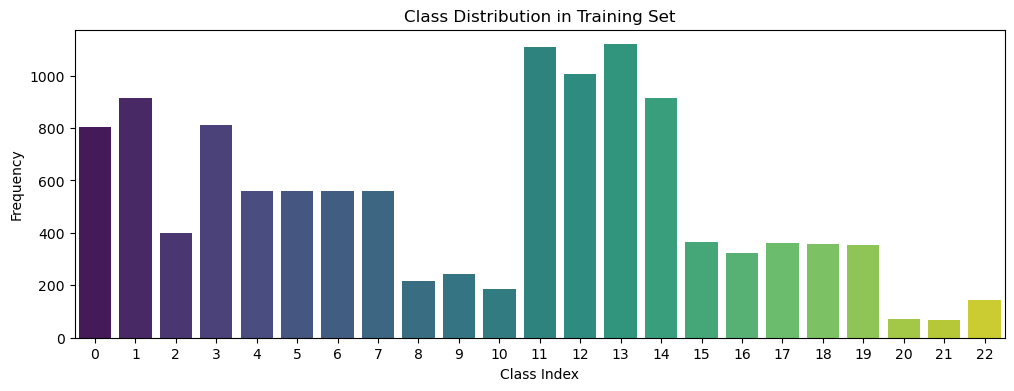

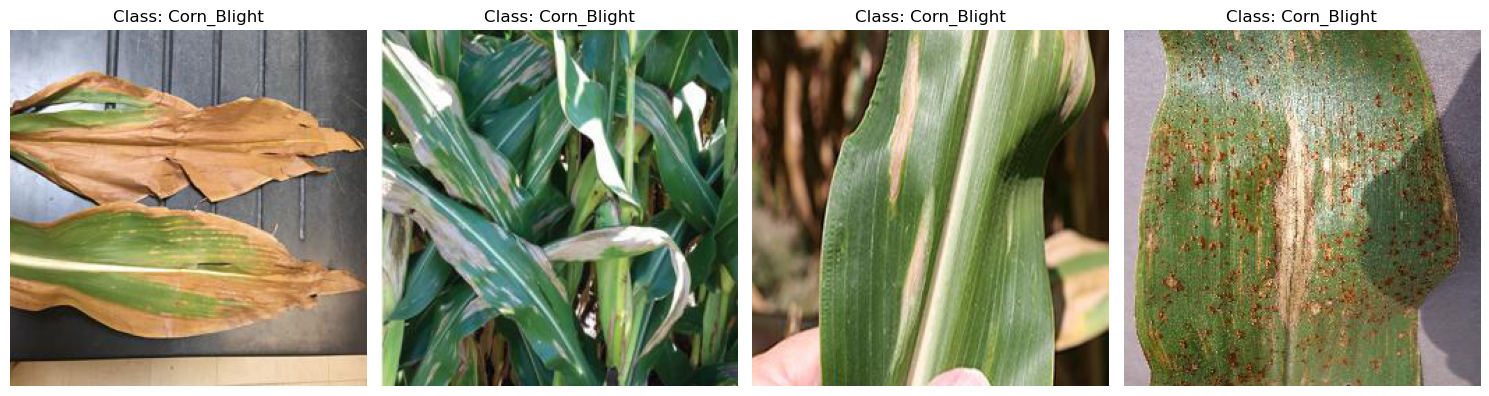

In [3]:
# Cell 3: EDA & Dataset Statistics
# Check feature types and class names
print('Dataset Features:', train_raw.features)

# Get class labels if available
if 'label' in train_raw.features:
  label_feature = train_raw.features['label']
  if hasattr(label_feature, 'names'):
    class_names = label_feature.names
  else:
    class_names = [str(i) for i in set(train_raw['label'])]
else:
  # Fallback if label is string or other format
  class_names = sorted(list(set(train_raw['label'])))

num_classes = len(class_names)
print(f'Total Number of Classes: {num_classes}')
print(f'Classes: {class_names}')

# Class distribution check
train_labels = [item['label'] for item in train_raw]
class_counts = Counter(train_labels)

plt.figure(figsize=(12, 4))
sns.barplot(
    x=list(class_counts.keys()),
    y=list(class_counts.values()),
    palette='viridis',
)
plt.title('Class Distribution in Training Set')
plt.xlabel('Class Index')
plt.ylabel('Frequency')
plt.show()

# Visualize sample images
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for i in range(4):
  sample = train_raw[i]
  img = sample['image']
  label = sample['label']
  axes[i].imshow(img)
  axes[i].set_title(
      f'Class: {class_names[label] if isinstance(label, int) else label}'
  )
  axes[i].axis('off')
plt.tight_layout()
plt.show()

In [4]:
# Cell 4: Feature Extraction and Label Encoding for Classical ML
from PIL import Image
import numpy as np
from sklearn.preprocessing import LabelEncoder

IMG_SIZE = (32, 32)  # Small size for classical ML memory limits


def extract_data(dataset_split, max_samples=1500):
  n = min(len(dataset_split), max_samples)
  X, y = [], []
  for i in range(n):
    img = dataset_split[i]['image'].convert('RGB').resize(IMG_SIZE)
    arr = np.array(img).flatten() / 255.0  # Normalize pixels
    X.append(arr)
    y.append(dataset_split[i]['label'])
  return np.array(X), np.array(y)


print('Preparing data for classical models...')
X_train_ml, y_train_raw = extract_data(train_raw, max_samples=1500)
X_test_ml, y_test_raw = extract_data(test_raw, max_samples=500)

# Fit LabelEncoder on the combined labels of the entire dataset to capture all classes
all_labels = list(train_raw['label']) + list(test_raw['label'])
encoder = LabelEncoder()
encoder.fit(all_labels)

# Transform both train and test arrays safely
y_train_ml = encoder.transform(y_train_raw)
y_test_ml = encoder.transform(y_test_raw)

print(f'ML Train Shape: {X_train_ml.shape}, ML Test Shape: {X_test_ml.shape}')
print(f'Number of Encoded Classes: {len(encoder.classes_)}')

Preparing data for classical models...
ML Train Shape: (1500, 3072), ML Test Shape: (500, 3072)
Number of Encoded Classes: 23


In [5]:
# Cell 5: Train and Evaluate Classical Models with Robust Metric Handling
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from sklearn.svm import SVC


def safe_metrics(y_true, y_pred):
  acc = accuracy_score(y_true, y_pred)
  # Calculate per-class metrics safely, ignoring classes with zero instances in the subset
  prec, rec, f1, _ = precision_recall_fscore_support(
      y_true, y_pred, average='weighted', zero_division=0
  )
  # Fallback to 0.0 if any metric returns None or NaN
  prec = float(prec) if prec is not None and not np.isnan(prec) else 0.0
  rec = float(rec) if rec is not None and not np.isnan(rec) else 0.0
  f1 = float(f1) if f1 is not None and not np.isnan(f1) else 0.0
  return acc, prec, rec, f1


models_dict = {
    'Logistic Regression': LogisticRegression(max_iter=300, random_state=42),
    'Random Forest': RandomForestClassifier(
        n_estimators=100, random_state=42
    ),
    'SVM': SVC(kernel='rbf', random_state=42),
}

for name, clf in models_dict.items():
  print(f'\n--- Training {name} ---')
  clf.fit(X_train_ml, y_train_ml)

  # Predictions
  train_preds = clf.predict(X_train_ml)
  test_preds = clf.predict(X_test_ml)

  # Safe Metrics
  tr_acc, tr_prec, tr_rec, tr_f1 = safe_metrics(y_train_ml, train_preds)
  te_acc, te_prec, te_rec, te_f1 = safe_metrics(y_test_ml, test_preds)

  print(
      f'Train -> Acc: {tr_acc:.4f} | Prec: {tr_prec:.4f} | Rec: {tr_rec:.4f} |'
      f' F1: {tr_f1:.4f}'
  )
  print(
      f'Test  -> Acc: {te_acc:.4f} | Prec: {te_prec:.4f} | Rec: {te_rec:.4f} |'
      f' F1: {te_f1:.4f}'
  )


--- Training Logistic Regression ---
Train -> Acc: 0.9967 | Prec: 0.9967 | Rec: 0.9967 | F1: 0.9967
Test  -> Acc: 0.4600 | Prec: 0.2607 | Rec: 0.4600 | F1: 0.3232

--- Training Random Forest ---
Train -> Acc: 1.0000 | Prec: 1.0000 | Rec: 1.0000 | F1: 1.0000
Test  -> Acc: 0.4560 | Prec: 0.2468 | Rec: 0.4560 | F1: 0.3135

--- Training SVM ---
Train -> Acc: 0.9760 | Prec: 0.9764 | Rec: 0.9760 | F1: 0.9760
Test  -> Acc: 0.4540 | Prec: 0.2650 | Rec: 0.4540 | F1: 0.3223


In [6]:
# Cell 6: Validation Split Creation
train_size = int(0.8 * len(train_raw))
val_size = len(train_raw) - train_size

train_subset, val_subset = random_split(
    train_raw,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42),
)
print(f'Training subset size: {len(train_subset)}')
print(f'Validation subset size: {len(val_subset)}')
print(f'Test set size: {len(test_raw)}')

Training subset size: 9601
Validation subset size: 2401
Test set size: 1731


In [7]:
# Cell 7: PyTorch Dataset & DataLoaders
class CropDataset(Dataset):

  def __init__(self, hf_subset, transform=None):
    self.hf_subset = hf_subset
    self.transform = transform

  def __len__(self):
    return len(self.hf_subset)

  def __getitem__(self, idx):
    item = self.hf_subset[idx]
    image = item['image'].convert('RGB')
    label = item['label']

    if self.transform:
      image = self.transform(image)

    return image, label


# Image transformations (Standard ImageNet normalization)
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

train_dataset = CropDataset(train_subset, transform=train_transform)
val_dataset = CropDataset(val_subset, transform=val_test_transform)
test_dataset = CropDataset(test_raw, transform=val_test_transform)

# 6GB VRAM friendly batch size (Batch size = 32)
BATCH_SIZE = 32
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)

In [8]:
# Cell 8: Model Architecture, Selection & Checkpoint Setup
import os
import torchvision.models as models

# --- CHOOSE YOUR MODEL HERE ---
# Options: 'resnet18', 'efficientnet_b0', 'mobilenet_v3_large', ''
MODEL_NAME = 'mobilenet_v3_small'

print(f'Loading pretrained {MODEL_NAME}...')

if MODEL_NAME == 'resnet18':
  model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
  num_ftrs = model.fc.in_features
  model.fc = nn.Linear(num_ftrs, len(class_names))

elif MODEL_NAME == 'efficientnet_b0':
  model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
  num_ftrs = model.classifier[1].in_features
  model.classifier[1] = nn.Linear(num_ftrs, len(class_names))

elif MODEL_NAME == 'mobilenet_v3_large':
  model = models.mobilenet_v3_large(
      weights=models.MobileNet_V3_Large_Weights.DEFAULT
  )
  num_ftrs = model.classifier[3].in_features
  model.classifier[3] = nn.Linear(num_ftrs, len(class_names))

elif MODEL_NAME == 'mobilenet_v3_small':
  model = models.mobilenet_v3_small(
      weights=models.MobileNet_V3_Small_Weights.DEFAULT
  )
  num_ftrs = model.classifier[3].in_features
  model.classifier[3] = nn.Linear(num_ftrs, len(class_names))


else:
  raise ValueError(f'Unknown model name: {MODEL_NAME}')

model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)

# --- FIXED CHECKPOINT PATH ---
# Appended a filename to your directory path so it points to a file, not a folder
CHECKPOINT_DIR = 'D:/Dev/projects/python/MLLab/checkpoints'
os.makedirs(CHECKPOINT_DIR, exist_ok=True)  # Ensure folder exists
CHECKPOINT_PATH = os.path.join(CHECKPOINT_DIR, f'{MODEL_NAME}_mobilenetv3-small_checkpoint.pth')

start_epoch = 0
best_val_acc = 0.0

# Check if checkpoint exists to resume training
if os.path.exists(CHECKPOINT_PATH):
  print(f'Found checkpoint: {CHECKPOINT_PATH}. Resuming training...')
  checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)
  model.load_state_dict(checkpoint['model_state_dict'])
  optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
  start_epoch = checkpoint['epoch'] + 1
  best_val_acc = checkpoint.get('best_val_acc', 0.0)
  print(f'Resumed successfully from Epoch {start_epoch}')
else:
  print(
      'No checkpoint found at specified path. Training model from scratch.'
  )

Loading pretrained mobilenet_v3_small...


Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to C:\Users\krris/.cache\torch\hub\checkpoints\mobilenet_v3_small-047dcff4.pth
100%|██████████| 9.83M/9.83M [00:08<00:00, 1.17MB/s]


No checkpoint found at specified path. Training model from scratch.


In [9]:
# Cell 9: Fine-tuning Loop with Resume Support
NUM_EPOCHS = 20

print(f'Starting training from epoch {start_epoch} to {NUM_EPOCHS}...')

for epoch in range(start_epoch, NUM_EPOCHS):
  model.train()
  running_loss = 0.0
  correct = 0
  total = 0

  loop = tqdm(train_loader, desc=f'Epoch [{epoch+1}/{NUM_EPOCHS}]')
  for images, labels in loop:
    images, labels = images.to(device), labels.to(device)

    optimizer.zero_grad()
    outputs = model(images)
    loss = criterion(outputs, labels)
    loss.backward()
    optimizer.step()

    running_loss += loss.item() * images.size(0)
    _, predicted = outputs.max(1)
    total += labels.size(0)
    correct += predicted.eq(labels).sum().item()

    loop.set_postfix(loss=loss.item(), acc=100.0 * correct / total)

  epoch_loss = running_loss / total
  epoch_acc = correct / total

  # Validation step
  model.eval()
  val_correct = 0
  val_total = 0
  with torch.no_grad():
    for images, labels in val_loader:
      images, labels = images.to(device), labels.to(device)
      outputs = model(images)
      _, predicted = outputs.max(1)
      val_total += labels.size(0)
      val_correct += predicted.eq(labels).sum().item()

  val_acc = val_correct / val_total
  print(
      f'Epoch {epoch+1} Finished | Train Loss: {epoch_loss:.4f} | Train Acc:'
      f' {epoch_acc:.4f} | Val Acc: {val_acc:.4f}'
  )

  # Save checkpoint after each epoch (enables resuming if interrupted)
  if val_acc > best_val_acc:
    best_val_acc = val_acc

  torch.save(
      {
          'epoch': epoch,
          'model_state_dict': model.state_dict(),
          'optimizer_state_dict': optimizer.state_dict(),
          'best_val_acc': best_val_acc,
      },
      CHECKPOINT_PATH,
  )
  print(f'Checkpoint saved at epoch {epoch+1} to {CHECKPOINT_PATH}')

print('Fine-tuning complete!')

Starting training from epoch 0 to 20...


Epoch [1/20]: 100%|██████████| 301/301 [01:43<00:00,  2.90it/s, acc=83.8, loss=2.22]  


Epoch 1 Finished | Train Loss: 0.4867 | Train Acc: 0.8384 | Val Acc: 0.8880
Checkpoint saved at epoch 1 to D:/Dev/projects/python/MLLab/checkpoints\mobilenet_v3_small_mobilenetv3-small_checkpoint.pth


Epoch [2/20]: 100%|██████████| 301/301 [01:44<00:00,  2.89it/s, acc=92.9, loss=7.41]  


Epoch 2 Finished | Train Loss: 0.2147 | Train Acc: 0.9293 | Val Acc: 0.8517
Checkpoint saved at epoch 2 to D:/Dev/projects/python/MLLab/checkpoints\mobilenet_v3_small_mobilenetv3-small_checkpoint.pth


...

Epoch 18 Finished | Train Loss: 0.0633 | Train Acc: 0.9780 | Val Acc: 0.9563
Checkpoint saved at epoch 18 to D:/Dev/projects/python/MLLab/checkpoints\mobilenet_v3_small_mobilenetv3-small_checkpoint.pth


Epoch [19/20]: 100%|██████████| 301/301 [00:40<00:00,  7.41it/s, acc=98.1, loss=3.24]    


Epoch 19 Finished | Train Loss: 0.0615 | Train Acc: 0.9805 | Val Acc: 0.9171
Checkpoint saved at epoch 19 to D:/Dev/projects/python/MLLab/checkpoints\mobilenet_v3_small_mobilenetv3-small_checkpoint.pth


Epoch [20/20]: 100%|██████████| 301/301 [00:44<00:00,  6.81it/s, acc=97.5, loss=9.19]    


Epoch 20 Finished | Train Loss: 0.0771 | Train Acc: 0.9752 | Val Acc: 0.9446
Checkpoint saved at epoch 20 to D:/Dev/projects/python/MLLab/checkpoints\mobilenet_v3_small_mobilenetv3-small_checkpoint.pth
Fine-tuning complete!


In [10]:
# Cell 10: Final Evaluation Metrics Calculation
def evaluate_model(model, data_loader, dataset_name='Dataset'):
  model.eval()
  all_preds = []
  all_targets = []

  with torch.no_grad():
    for images, labels in data_loader:
      images = images.to(device)
      outputs = model(images)
      _, preds = torch.max(outputs, 1)
      all_preds.extend(preds.cpu().numpy())
      all_targets.extend(labels.numpy())

  acc = accuracy_score(all_targets, all_preds)
  precision, recall, f1, _ = precision_recall_fscore_support(
      all_targets, all_preds, average='weighted', zero_division=0
  )

  print(f'--- {dataset_name} Evaluation ---')
  print(f'Accuracy  : {acc:.4f}')
  print(f'Precision : {precision:.4f}')
  print(f'Recall    : {recall:.4f}')
  print(f'F1-Score  : {f1:.4f}\n')
  return acc, precision, recall, f1


# Load best checkpoint before final evaluation
if os.path.exists(CHECKPOINT_PATH):
  checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)
  model.load_state_dict(checkpoint['model_state_dict'])
  print('Loaded best model weights for final evaluation.')

# Evaluate on Train and Test Sets
evaluate_model(model, train_loader, dataset_name='Training Set')
evaluate_model(model, test_loader, dataset_name='Test Set')

C:\Users\krris\AppData\Local\Temp\ipykernel_1488\426759701.py:30: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)

Loaded best model weights for final evaluation.
--- Training Set Evaluation ---
Accuracy  : 0.9789
Precision : 0.9792
Recall    : 0.9789
F1-Score  : 0.9788

--- Test Set Evaluation ---
Accuracy  : 0.9492
Precision : 0.9501
Recall    : 0.9492
F1-Score  : 0.9491



(0.9491623339110341,
 0.9500917709817716,
 0.9491623339110341,
 0.9490781711827019)


## ResNet

C:\Users\krris\AppData\Local\Temp\ipykernel_13408\426759701.py:30: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)
Loaded best model weights for final evaluation.
--- Training Set Evaluation ---
Accuracy  : 0.9667
Precision : 0.9712
Recall    : 0.9667
F1-Score  : 0.9659

--- Test Set Evaluation ---
Accuracy  : 0.9370
Precision : 0.9440
Recall    : 0.9370
F1-Score  : 0.9357

### Efficient net b0

C:\Users\krris\AppData\Local\Temp\ipykernel_13408\426759701.py:30: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)
Loaded best model weights for final evaluation.
--- Training Set Evaluation ---
Accuracy  : 0.9882
Precision : 0.9896
Recall    : 0.9882
F1-Score  : 0.9880

--- Test Set Evaluation ---
Accuracy  : 0.9636
Precision : 0.9681
Recall    : 0.9636
F1-Score  : 0.9626

### mobilenet_v3_large
C:\Users\krris\AppData\Local\Temp\ipykernel_10776\426759701.py:30: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)
Loaded best model weights for final evaluation.
--- Training Set Evaluation ---
Accuracy  : 0.9843
Precision : 0.9852
Recall    : 0.9843
F1-Score  : 0.9844

--- Test Set Evaluation ---
Accuracy  : 0.9538
Precision : 0.9578
Recall    : 0.9538
F1-Score  : 0.9540

### mobilenet_v3_small

C:\Users\krris\AppData\Local\Temp\ipykernel_1488\426759701.py:30: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)
Loaded best model weights for final evaluation.
--- Training Set Evaluation ---
Accuracy  : 0.9789
Precision : 0.9792
Recall    : 0.9789
F1-Score  : 0.9788

--- Test Set Evaluation ---
Accuracy  : 0.9492
Precision : 0.9501
Recall    : 0.9492
F1-Score  : 0.9491